# 04b — SARIMA com Seleção Automática de Ordem (Auto-ARIMA)

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: OE2 — Avaliação definitiva do SARIMA

---
### ⚠️ Aviso de tempo
Este notebook pode demorar **2–6 horas** para 200 séries.  
Recomenda-se **rodar overnight** ou em segundo plano.

### Estratégia de busca
A seleção de ordem usa busca em grade limitada sobre o espaço:
- `p ∈ {0,1,2}`, `d ∈ {0,1}`, `q ∈ {0,1,2}`
- `P ∈ {0,1}`, `D ∈ {0,1}`, `Q ∈ {0,1}`, `m=12`

Para cada série, seleciona a combinação com **menor AIC** entre as que convergiram.  
Fallback para a ordem heurística `(1,1,1)(1,1,0)[12]` se nenhuma convergir.

### Relação com o notebook 04
A comparação entre `04_sarima_heuristic` e `04b_sarima_auto` quantifica o
**custo da restrição operacional** — dado direto para a seção 5.2 da dissertação.

## 1. Imports e configurações

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
import warnings
import time
import json
from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings('ignore')

# ── Caminhos (funciona com cwd em autopred/ ou notebooks/) ───────────────────
import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'paths.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.paths import DATA_DIR, PROJECT_ROOT, RESULT_DIR

RESULT_DIR.mkdir(parents=True, exist_ok=True)

_required = {
    'Monthly-train.csv': DATA_DIR / 'Monthly-train.csv',
    'Monthly-test.csv':  DATA_DIR / 'Monthly-test.csv',
}
_missing = [name for name, p in _required.items() if not p.is_file()]
if _missing:
    raise FileNotFoundError(
        f'Arquivos não encontrados em {DATA_DIR}: {_missing}\n'
        f'PROJECT_ROOT = {PROJECT_ROOT}'
    )
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR       = {DATA_DIR}  OK')
print(f'RESULT_DIR     = {RESULT_DIR}')

SEED      = 42
H         = 18
MIN_TRAIN = 24
N_ORIGINS = 3
PILOT_N   = 200

# ── Espaço de busca (grade limitada para viabilidade computacional) ───────────
SEARCH_SPACE = {
    'p': [0, 1, 2],
    'd': [0, 1],
    'q': [0, 1, 2],
    'P': [0, 1],
    'D': [0, 1],
    'Q': [0, 1],
    'm': [12]
}

# Ordem fallback se nenhuma combinação convergir
FALLBACK_ORDER          = (1, 1, 1)
FALLBACK_SEASONAL_ORDER = (1, 1, 0, 12)

# Limite de tempo por SÉRIE (não por janela)
TIME_LIMIT_PER_SERIES_S = 300.0   # 5 minutos por série

np.random.seed(SEED)

# Conta combinações
from itertools import product
combos = list(product(
    SEARCH_SPACE['p'], SEARCH_SPACE['d'], SEARCH_SPACE['q'],
    SEARCH_SPACE['P'], SEARCH_SPACE['D'], SEARCH_SPACE['Q']
))
print(f'Configuração carregada OK')
print(f'  Combinações na grade : {len(combos)}')
print(f'  Limite por série     : {TIME_LIMIT_PER_SERIES_S}s ({TIME_LIMIT_PER_SERIES_S/60:.1f} min)')
print(f'  Estimativa total     : {PILOT_N * TIME_LIMIT_PER_SERIES_S / 3600:.1f}h (pior caso)')

PROJECT_ROOT = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred
DATA_DIR       = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw  OK
RESULT_DIR     = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results
Configuração carregada OK
  Combinações na grade : 144
  Limite por série     : 300.0s (5.0 min)
  Estimativa total     : 16.7h (pior caso)


## 2. Funções base

In [2]:
def load_m4_monthly(data_dir):
    train_raw = pd.read_csv(data_dir / 'Monthly-train.csv')
    test_raw  = pd.read_csv(data_dir / 'Monthly-test.csv')
    def wide_to_long(df):
        id_col = df.columns[0]
        melted = df.melt(id_vars=id_col, value_vars=df.columns[1:],
                         var_name='step_raw', value_name='y')
        melted = melted.rename(columns={id_col: 'unique_id'})
        melted['step'] = melted['step_raw'].str.extract(r'(\d+)').astype(int)
        melted = melted.drop(columns='step_raw').dropna(subset=['y'])
        return melted.sort_values(['unique_id','step']).reset_index(drop=True)
    return wide_to_long(train_raw), wide_to_long(test_raw)

def make_rolling_windows(series, horizon, min_train, n_origins):
    n = len(series)
    if n < min_train + horizon:
        return []
    last_origin  = n - horizon
    first_origin = min_train
    if last_origin <= first_origin:
        return []
    origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
    origins = sorted(set(origins))
    return [
        {'origin': o, 'train': series[:o], 'test': series[o:o+horizon]}
        for o in origins if len(series[o:o+horizon]) == horizon
    ]

def calc_mape(y_true, y_pred):
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100)

def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }

print('Funções base OK')

Funções base OK


## 3. Carregamento e piloto

In [3]:
train_df, test_df = load_m4_monthly(DATA_DIR)
rng       = np.random.default_rng(SEED)
pilot_ids = rng.choice(train_df['unique_id'].unique(), size=PILOT_N, replace=False)
train_pilot = train_df[train_df['unique_id'].isin(pilot_ids)].copy()
print(f'Piloto: {PILOT_N} séries | {len(train_pilot):,} linhas')

Piloto: 200 séries | 44,224 linhas


## 4. Seleção automática de ordem por AIC

**Estratégia por série** (não por janela):
1. Usa a série de treino completa (última janela) para selecionar a melhor ordem
2. Aplica essa ordem fixada em todas as janelas da mesma série

Isso evita re-selecionar a ordem em cada janela (que triplicaria o tempo) e é metodologicamente
defensável porque a estrutura da série não muda substancialmente entre janelas.

In [4]:
def select_sarima_order(series, search_space=SEARCH_SPACE,
                        fallback_order=FALLBACK_ORDER,
                        fallback_seasonal=FALLBACK_SEASONAL_ORDER,
                        time_limit=TIME_LIMIT_PER_SERIES_S):
    """
    Busca em grade limitada para selecionar a ordem SARIMA com menor AIC.
    Retorna (order, seasonal_order, best_aic, n_convergiu).
    """
    best_order    = fallback_order
    best_seasonal = fallback_seasonal
    best_aic      = np.inf
    n_convergiu   = 0
    t_start       = time.perf_counter()

    combos = list(product(
        search_space['p'], search_space['d'], search_space['q'],
        search_space['P'], search_space['D'], search_space['Q']
    ))

    for p, d, q, P, D, Q in combos:
        # Verifica limite de tempo
        if time.perf_counter() - t_start > time_limit:
            break

        # Pula combinações triviais
        if p == 0 and q == 0 and P == 0 and Q == 0:
            continue

        try:
            m = SARIMAX(
                series,
                order          = (p, d, q),
                seasonal_order = (P, D, Q, 12),
                enforce_stationarity  = False,
                enforce_invertibility = False
            ).fit(disp=False, maxiter=50)

            if m.aic < best_aic:
                best_aic      = m.aic
                best_order    = (p, d, q)
                best_seasonal = (P, D, Q, 12)
            n_convergiu += 1

        except Exception:
            continue

    return best_order, best_seasonal, best_aic, n_convergiu


print('Função de seleção definida OK')
print(f'Testando com 1 série para verificar...')

np.random.seed(SEED)
ex = np.tile([100,105,110,115,120,125,120,115,110,105,100,95], 4).astype(float)
ex += np.random.normal(0, 3, len(ex))

t0 = time.time()
o, so, aic, n_conv = select_sarima_order(ex, time_limit=60)
print(f'  Melhor ordem : {o}{so}')
print(f'  AIC          : {aic:.2f}')
print(f'  Convergiu    : {n_conv} combinações')
print(f'  Tempo        : {time.time()-t0:.1f}s')

Função de seleção definida OK
Testando com 1 série para verificar...
  Melhor ordem : (0, 0, 2)(1, 1, 1, 12)
  AIC          : 111.24
  Convergiu    : 140 combinações
  Tempo        : 9.5s


## 5. Pipeline completo com seleção por série

In [5]:
def run_sarima_auto_pipeline(train_df, horizon, min_train, n_origins,
                             time_limit_per_series):
    """
    Para cada série:
      1. Seleciona melhor ordem por AIC na série completa
      2. Aplica essa ordem em todas as janelas rolling origin
    Registra ordem selecionada, AIC, n_convergiu e métricas por janela.
    """
    records      = []
    order_log    = []   # log das ordens selecionadas por série
    ids          = train_df['unique_id'].unique()
    total        = len(ids)

    for i, uid in enumerate(ids):
        if (i+1) % 20 == 0 or i == 0:
            elapsed = time.time() - t_pipeline_start
            print(f'  [{i+1:3d}/{total}] | {elapsed/60:.1f} min decorridos')

        values  = train_df[train_df['unique_id']==uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)

        if not windows:
            records.append({
                'unique_id':'uid','model':'sarima_auto',
                'origin':None,'n_train':None,
                'mape':None,'mae':None,'r2':None,
                'exec_time_s':None,'status':'SKIP_SHORT',
                'best_order':None,'best_seasonal':None,'n_convergiu':0
            })
            continue

        # Seleção de ordem na série completa (janela mais longa)
        t_sel = time.perf_counter()
        best_order, best_seasonal, best_aic, n_conv = select_sarima_order(
            values, time_limit=time_limit_per_series
        )
        t_sel_elapsed = time.perf_counter() - t_sel

        order_log.append({
            'unique_id'    : uid,
            'best_order'   : str(best_order),
            'best_seasonal': str(best_seasonal),
            'best_aic'     : round(best_aic, 2),
            'n_convergiu'  : n_conv,
            'sel_time_s'   : round(t_sel_elapsed, 2)
        })

        # Aplica ordem selecionada em cada janela
        for win in windows:
            t0 = time.perf_counter()
            try:
                m = SARIMAX(
                    win['train'],
                    order          = best_order,
                    seasonal_order = best_seasonal,
                    enforce_stationarity  = False,
                    enforce_invertibility = False
                ).fit(disp=False, maxiter=50)
                pred    = np.array(m.forecast(steps=horizon))
                metrics = calc_metrics(win['test'], pred)
                status  = 'OK'
            except Exception as e:
                metrics = {'mape':None,'mae':None,'r2':None}
                status  = f'ERROR: {str(e)[:80]}'
            elapsed = time.perf_counter() - t0

            records.append({
                'unique_id'    : uid,
                'model'        : 'sarima_auto',
                'origin'       : win['origin'],
                'n_train'      : len(win['train']),
                **metrics,
                'exec_time_s'  : elapsed,
                'status'       : status,
                'best_order'   : str(best_order),
                'best_seasonal': str(best_seasonal),
                'n_convergiu'  : n_conv
            })

    return pd.DataFrame(records), pd.DataFrame(order_log)

print('Pipeline auto-SARIMA definido OK')

Pipeline auto-SARIMA definido OK


## 6. Execução

> **⚠️ Recomenda-se rodar overnight.**  
> O progresso é salvo a cada 20 séries no log de ordens.  
> Se interrompido, os resultados parciais ficam em `results/results_sarima_auto_by_window.csv`.

In [6]:
print(f'Iniciando SARIMA auto em {PILOT_N} séries...')
print(f'Espaço de busca: {len(combos)} combinações por série')
print(f'Limite por série: {TIME_LIMIT_PER_SERIES_S}s\n')

t_pipeline_start = time.time()

results_auto, order_log_df = run_sarima_auto_pipeline(
    train_df               = train_pilot,
    horizon                = H,
    min_train              = MIN_TRAIN,
    n_origins              = N_ORIGINS,
    time_limit_per_series  = TIME_LIMIT_PER_SERIES_S
)

elapsed_total = time.time() - t_pipeline_start
print(f'\nConcluído em {elapsed_total/3600:.2f} horas ({elapsed_total/60:.1f} min)')

# Salva checkpoint imediato
results_auto.to_csv(RESULT_DIR / 'results_sarima_auto_by_window.csv', index=False)
order_log_df.to_csv(RESULT_DIR / 'sarima_auto_order_log.csv', index=False)
print('Checkpoint salvo!')

Iniciando SARIMA auto em 200 séries...
Espaço de busca: 144 combinações por série
Limite por série: 300.0s

  [  1/200] | 0.0 min decorridos
  [ 20/200] | 9.8 min decorridos
  [ 40/200] | 17.6 min decorridos
  [ 60/200] | 27.7 min decorridos
  [ 80/200] | 38.7 min decorridos
  [100/200] | 49.3 min decorridos
  [120/200] | 57.9 min decorridos
  [140/200] | 68.0 min decorridos
  [160/200] | 78.0 min decorridos
  [180/200] | 84.9 min decorridos
  [200/200] | 92.9 min decorridos

Concluído em 1.55 horas (93.1 min)
Checkpoint salvo!


## 7. Análise de resultados

In [7]:
status_counts = results_auto['status'].value_counts()
print('=== Status da execução ===')
print(status_counts.to_string())

ok_auto   = results_auto[results_auto['status'] == 'OK']
n_tent    = results_auto['origin'].notna().sum()
taxa_ok   = 100 * len(ok_auto) / n_tent if n_tent > 0 else 0

by_series_auto = (
    ok_auto.groupby('unique_id')[['mape','mae','r2','exec_time_s']]
    .median().reset_index()
)

print(f'\n=== Desempenho SARIMA auto ===')
print(f'  Taxa sucesso : {taxa_ok:.1f}%')
print(f'  MAPE mediano : {by_series_auto["mape"].median():.4f}%')
print(f'  MAE  mediano : {by_series_auto["mae"].median():.4f}')
print(f'  R²   mediano : {by_series_auto["r2"].median():.4f}')
print(f'  Tempo mediano: {by_series_auto["exec_time_s"].median():.4f}s/janela')

=== Status da execução ===
status
OK    600

=== Desempenho SARIMA auto ===
  Taxa sucesso : 100.0%
  MAPE mediano : 9.1184%
  MAE  mediano : 266.3902
  R²   mediano : -1.2678
  Tempo mediano: 0.2127s/janela


## 8. Comparação: SARIMA auto vs SARIMA heurístico

In [9]:
# Carrega heurístico para comparação
heur_path = RESULT_DIR / 'results_sarima_heuristic_by_series.csv'

if heur_path.exists():
    heur_df = pd.read_csv(heur_path)

    comp = pd.DataFrame({
        'SARIMA heurístico': [
            heur_df['mape'].median(),
            heur_df['mae'].median(),
            heur_df['r2'].median(),
            heur_df['exec_time_s'].median()
        ],
        'SARIMA auto (AIC)': [
            by_series_auto['mape'].median(),
            by_series_auto['mae'].median(),
            by_series_auto['r2'].median(),
            by_series_auto['exec_time_s'].median()
        ]
    }, index=['MAPE (%)', 'MAE', 'R²', 'Tempo mediano (s)'])

    comp['Ganho auto (%)'] = (
        (comp['SARIMA heurístico'] - comp['SARIMA auto (AIC)'])
        / comp['SARIMA heurístico'].abs() * 100
    ).round(2)

    print('=== Custo da restrição operacional (seção 5.2) ===')
    print(comp.round(4).to_string())
    comp.to_csv(RESULT_DIR / 'comparacao_sarima_heuristic_vs_auto.csv')
else:
    print('Arquivo do notebook 04 não encontrado.')
    print('Execute o notebook 04_sarima_heuristic.ipynb primeiro.')

=== Custo da restrição operacional (seção 5.2) ===
                   SARIMA heurístico  SARIMA auto (AIC)  Ganho auto (%)
MAPE (%)                     10.0628             9.1184            9.39
MAE                         284.7858           266.3902            6.46
R²                           -2.0551            -1.2678          -38.31
Tempo mediano (s)             0.0990             0.2127         -114.73


## 9. Análise das ordens selecionadas

=== Ordens mais frequentes selecionadas pelo auto-SARIMA ===
best_order
(0, 1, 2)    78
(2, 1, 2)    76
(1, 1, 2)    43
(2, 1, 1)     2
(2, 0, 2)     1

=== Ordens sazonais mais frequentes ===
best_seasonal
(0, 1, 1, 12)    133
(1, 1, 1, 12)     66
(1, 0, 0, 12)      1

Convergência média por série: 140.0 combinações
Tempo médio de seleção: 27.2s


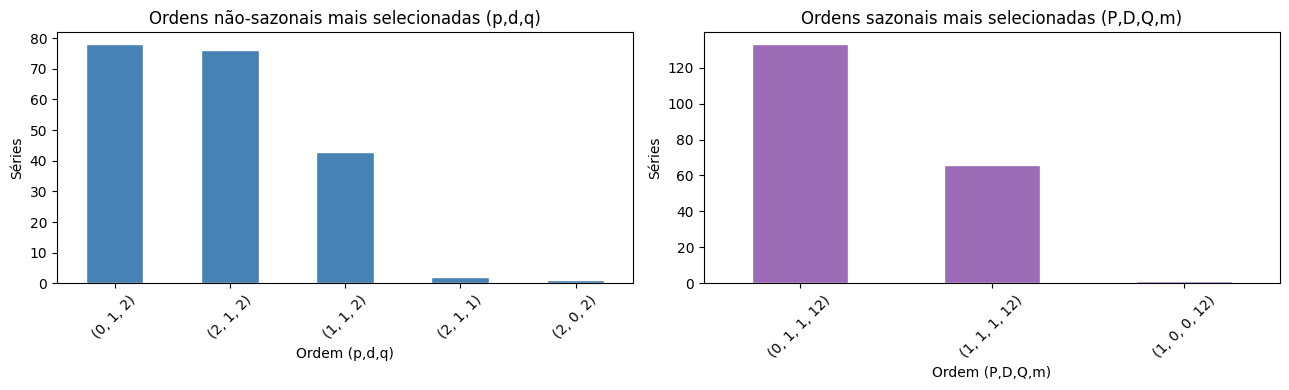

In [10]:
print('=== Ordens mais frequentes selecionadas pelo auto-SARIMA ===')
order_counts = order_log_df['best_order'].value_counts().head(10)
print(order_counts.to_string())

print('\n=== Ordens sazonais mais frequentes ===')
seasonal_counts = order_log_df['best_seasonal'].value_counts().head(10)
print(seasonal_counts.to_string())

print(f'\nConvergência média por série: {order_log_df["n_convergiu"].mean():.1f} combinações')
print(f'Tempo médio de seleção: {order_log_df["sel_time_s"].mean():.1f}s')

# Gráfico de distribuição das ordens
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

order_counts.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Ordens não-sazonais mais selecionadas (p,d,q)')
axes[0].set_xlabel('Ordem (p,d,q)')
axes[0].set_ylabel('Séries')
axes[0].tick_params(axis='x', rotation=45)

seasonal_counts.plot(kind='bar', ax=axes[1], color='#9B6BB5', edgecolor='white')
axes[1].set_title('Ordens sazonais mais selecionadas (P,D,Q,m)')
axes[1].set_xlabel('Ordem (P,D,Q,m)')
axes[1].set_ylabel('Séries')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_sarima_auto_ordens.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Tabela comparativa acumulada final

In [11]:
prev_path = RESULT_DIR / 'tabela_acumulada_nb04_sarima_heuristic.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path, index_col=0)
    auto_row = pd.DataFrame([{
        'MAPE (%)' : round(by_series_auto['mape'].median(), 4),
        'MAE'      : round(by_series_auto['mae'].median(),  4),
        'R²'       : round(by_series_auto['r2'].median(),   4),
        'Tempo (s)': round(by_series_auto['exec_time_s'].median(), 4),
    }], index=['SARIMA auto (AIC)'])
    summary = pd.concat([prev, auto_row]).sort_values('MAPE (%)')
else:
    summary = pd.DataFrame([{
        'MAPE (%)' : round(by_series_auto['mape'].median(), 4),
        'MAE'      : round(by_series_auto['mae'].median(),  4),
        'R²'       : round(by_series_auto['r2'].median(),   4),
        'Tempo (s)': round(by_series_auto['exec_time_s'].median(), 4),
    }], index=['SARIMA auto (AIC)'])

print('=== Tabela comparativa acumulada ===')
print(summary.to_string())
summary.to_csv(RESULT_DIR / 'tabela_acumulada_nb04b_sarima_auto.csv')
print('\nTabela salva em results/tabela_acumulada_nb04b_sarima_auto.csv')

=== Tabela comparativa acumulada ===
                   MAPE (%)       MAE      R²  Tempo (s)
Holt-Winters         8.2606  256.0183 -1.0642     0.1852
Persistência         8.6992  274.1667 -1.2684     0.0004
SES                  8.7764  253.5196 -1.1898     0.0038
SARIMA auto (AIC)    9.1184  266.3902 -1.2678     0.2127
SARIMA heurístico   10.0628  284.7858 -2.0551     0.0990
Sazonal ingênuo     11.0601  316.8889 -2.1744     0.0004
Média histórica     18.5971  589.9421 -6.4779     0.0004

Tabela salva em results/tabela_acumulada_nb04b_sarima_auto.csv


## 11. Salvando artefatos finais

In [12]:
by_series_auto.assign(model='sarima_auto').to_csv(
    RESULT_DIR / 'results_sarima_auto_by_series.csv', index=False
)

run_log = {
    'timestamp'            : datetime.now().isoformat(),
    'notebook'             : '04b_sarima_auto',
    'model'                : 'sarima_auto',
    'search_space'         : SEARCH_SPACE,
    'n_combinations'       : len(combos),
    'time_limit_per_series': TIME_LIMIT_PER_SERIES_S,
    'dataset'              : 'M4_Monthly',
    'pilot_n'              : PILOT_N,
    'seed'                 : SEED,
    'horizon_H'            : H,
    'n_ok'                 : int(len(ok_auto)),
    'taxa_sucesso'         : round(taxa_ok, 2),
    'mape_median'          : round(float(by_series_auto['mape'].median()), 4),
    'mae_median'           : round(float(by_series_auto['mae'].median()),  4),
    'r2_median'            : round(float(by_series_auto['r2'].median()),   4),
    'elapsed_total_min'    : round(elapsed_total/60, 2),
}

with open(RESULT_DIR / 'run_log_sarima_auto.json', 'w') as f:
    json.dump(run_log, f, indent=2)

print('Artefatos salvos:')
print('  results_sarima_auto_by_window.csv')
print('  results_sarima_auto_by_series.csv')
print('  sarima_auto_order_log.csv')
print('  comparacao_sarima_heuristic_vs_auto.csv')
print('  run_log_sarima_auto.json')
print()
print(json.dumps(run_log, indent=2))

Artefatos salvos:
  results_sarima_auto_by_window.csv
  results_sarima_auto_by_series.csv
  sarima_auto_order_log.csv
  comparacao_sarima_heuristic_vs_auto.csv
  run_log_sarima_auto.json

{
  "timestamp": "2026-05-22T19:57:38.448566",
  "notebook": "04b_sarima_auto",
  "model": "sarima_auto",
  "search_space": {
    "p": [
      0,
      1,
      2
    ],
    "d": [
      0,
      1
    ],
    "q": [
      0,
      1,
      2
    ],
    "P": [
      0,
      1
    ],
    "D": [
      0,
      1
    ],
    "Q": [
      0,
      1
    ],
    "m": [
      12
    ]
  },
  "n_combinations": 144,
  "time_limit_per_series": 300.0,
  "dataset": "M4_Monthly",
  "pilot_n": 200,
  "seed": 42,
  "horizon_H": 18,
  "n_ok": 600,
  "taxa_sucesso": 100.0,
  "mape_median": 9.1184,
  "mae_median": 266.3902,
  "r2_median": -1.2678,
  "elapsed_total_min": 93.13
}


## 12. Próximos passos

---

Com os dois notebooks SARIMA completos, a dissertação terá:

| Comparação | Dado gerado |
|---|---|
| Heurístico vs Auto | Custo da restrição operacional |
| SARIMA vs HW/SES | Comparação entre famílias estatísticas |
| SARIMA vs baselines ingênuos | Justificativa do uso de modelos complexos |

---

### Próximo notebook: `05_random_forest.ipynb`
- Primeiro modelo baseado em árvores de decisão
- Engenharia de features temporais (lags + estatísticas de janela)
- Importância de features nativa (base para análise SHAP)